<a href="https://colab.research.google.com/github/IvanRUDN/IST2026_autumn/blob/main/d2lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# D2Lab — исследование PCA и kNN на изображениях цифр

Цель работы — уменьшить число признаков изображений и проверить, как это отражается на распознавании цифр.

## 1. Загрузка и просмотр данных

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


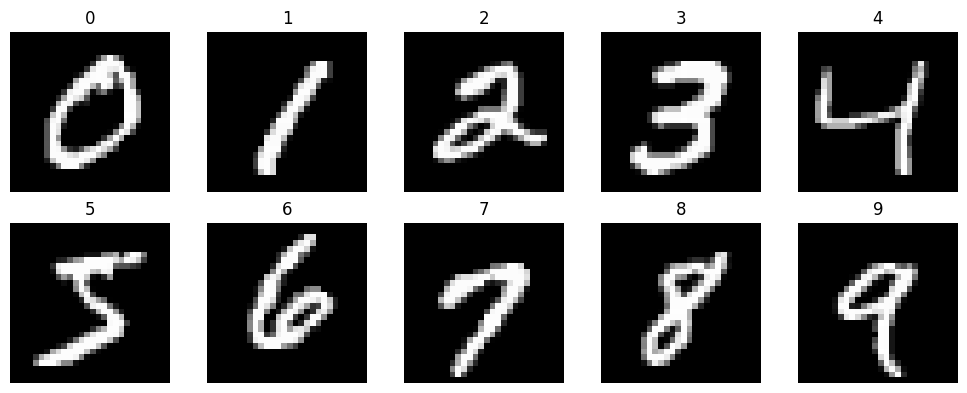

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time
from tensorflow.keras.datasets import mnist
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

(X_train_img, y_train_all), (X_test_img, y_test_all) = mnist.load_data()

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit, ax in enumerate(axes.ravel()):
    idx = np.where(y_train_all == digit)[0][0]
    ax.imshow(X_train_img[idx], cmap="gray")
    ax.set_title(str(digit))
    ax.axis("off")
plt.tight_layout()
plt.show()

Для экспериментов использую часть набора, чтобы расчёты выполнялись быстрее в Colab. Изображение 28×28 разворачивается в вектор из 784 значений.

In [ ]:
rng = np.random.default_rng(42)
train_ids = rng.choice(len(X_train_img), 8000, replace=False)
test_ids = rng.choice(len(X_test_img), 2000, replace=False)

X_train = X_train_img[train_ids].reshape(len(train_ids), -1).astype("float32") / 255
y_train = y_train_all[train_ids]
X_test = X_test_img[test_ids].reshape(len(test_ids), -1).astype("float32") / 255
y_test = y_test_all[test_ids]

print("Обучение:", X_train.shape, y_train.shape)
print("Тест:", X_test.shape, y_test.shape)
print("Число признаков:", X_train.shape[1])

Обучение: (8000, 784) (8000,)
Тест: (2000, 784) (2000,)
Число признаков: 784


## 2. Собственная реализация PCA

In [ ]:
class my_PCA:
    def __init__(self, n_components=None):
        self.n_components = n_components

    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        centered = X - self.mean_
        _, singular_values, vectors = np.linalg.svd(centered, full_matrices=False)
        variance = singular_values ** 2 / (len(X) - 1)
        count = self.n_components or len(variance)
        self.components_ = vectors[:count]
        self.explained_variance_ = variance[:count]
        self.all_variance_ = variance
        return self

    def transform(self, X):
        return (X - self.mean_) @ self.components_.T

    def fit_transform(self, X):
        return self.fit(X).transform(X)

### Проверка на библиотечной реализации

In [ ]:
pca_custom = my_PCA(40)
Z_custom = pca_custom.fit_transform(X_train[:1500])
pca_library = PCA(n_components=40, svd_solver="full")
Z_library = pca_library.fit_transform(X_train[:1500])

print("Размер результата:", Z_custom.shape)
print("Сумма дисперсий, собственная реализация:", round(pca_custom.explained_variance_.sum(), 4))
print("Сумма дисперсий, sklearn:", round(pca_library.explained_variance_.sum(), 4))
print("Разница сумм:", round(abs(pca_custom.explained_variance_.sum() - pca_library.explained_variance_.sum()), 6))

Размер результата: (1500, 40)
Сумма дисперсий, собственная реализация: 42.0896
Сумма дисперсий, sklearn: 42.0896
Разница сумм: 8e-06


### Дисперсия главных компонент

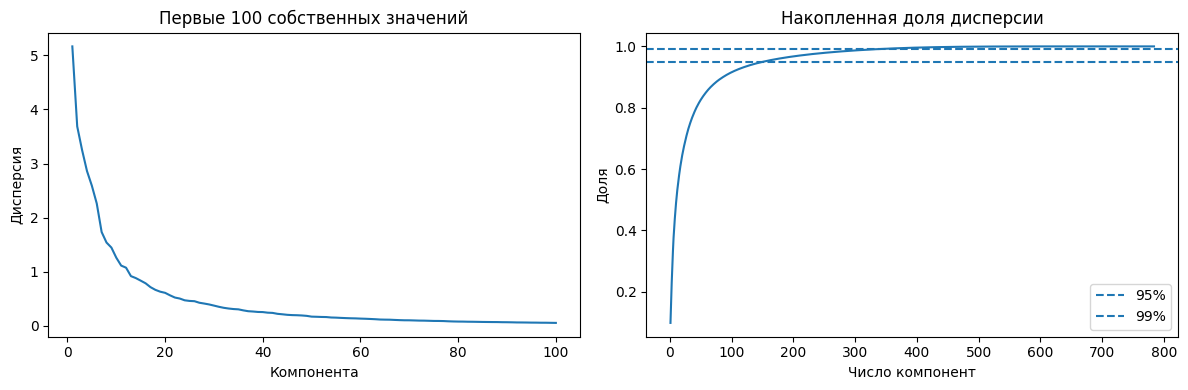

Доля дисперсии первых 15 компонент: 0.5803
Компонент для 95% дисперсии: 152


In [ ]:
pca_all = my_PCA()
pca_all.fit(X_train)
variance_share = pca_all.all_variance_ / pca_all.all_variance_.sum()
cumulative_share = np.cumsum(variance_share)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(np.arange(1, 101), pca_all.all_variance_[:100])
ax[0].set(title="Первые 100 собственных значений", xlabel="Компонента", ylabel="Дисперсия")
ax[1].plot(np.arange(1, len(cumulative_share) + 1), cumulative_share)
ax[1].axhline(.95, linestyle="--", label="95%")
ax[1].axhline(.99, linestyle="--", label="99%")
ax[1].set(title="Накопленная доля дисперсии", xlabel="Число компонент", ylabel="Доля")
ax[1].legend()
plt.tight_layout()
plt.show()

print("Доля дисперсии первых 15 компонент:", round(cumulative_share[14], 4))
print("Компонент для 95% дисперсии:", np.searchsorted(cumulative_share, .95) + 1)

### Отображение объектов в двумерном пространстве

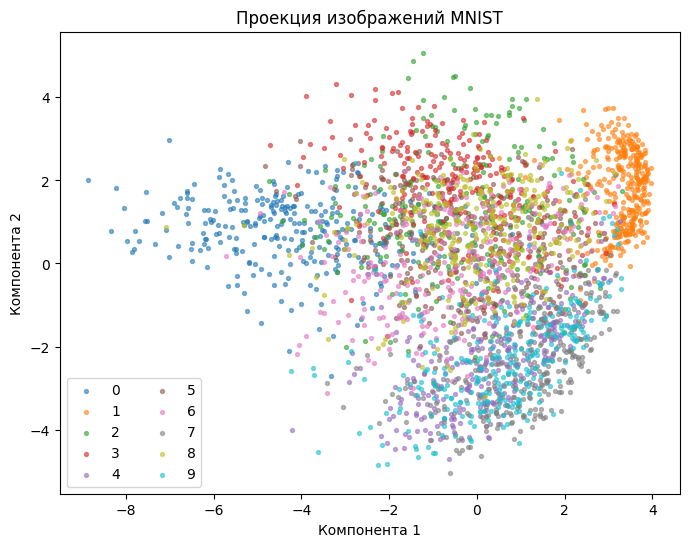

In [ ]:
pca_view = my_PCA(2)
points = pca_view.fit_transform(X_train[:3000])
plt.figure(figsize=(8, 6))
for digit in range(10):
    mask = y_train[:3000] == digit
    plt.scatter(points[mask, 0], points[mask, 1], s=8, alpha=.55, label=str(digit))
plt.xlabel("Компонента 1")
plt.ylabel("Компонента 2")
plt.title("Проекция изображений MNIST")
plt.legend(ncol=2)
plt.show()

На двумерной проекции классы обычно частично пересекаются: две компоненты сохраняют лишь часть информации, необходимой для различения похожих рукописных цифр.

## 3. Собственная реализация kNN

In [ ]:
class my_kNN:
    def __init__(self, n_neighbors=5):
        self.n_neighbors = n_neighbors

    def fit(self, X, y):
        self.X_train = np.asarray(X)
        self.y_train = np.asarray(y)
        return self

    def predict(self, X):
        predictions = []
        train_norm = np.sum(self.X_train ** 2, axis=1)
        for start in range(0, len(X), 100):
            batch = X[start:start + 100]
            distances = (np.sum(batch ** 2, axis=1)[:, None] + train_norm[None, :] - 2 * batch @ self.X_train.T)
            nearest = np.argpartition(distances, self.n_neighbors - 1, axis=1)[:, :self.n_neighbors]
            for ids in nearest:
                labels, counts = np.unique(self.y_train[ids], return_counts=True)
                predictions.append(labels[np.argmax(counts)])
        return np.array(predictions)

### Сравнение классификаторов

In [ ]:
small_train = X_train[:2500]
small_labels = y_train[:2500]
small_test = X_test[:500]
small_test_labels = y_test[:500]

custom_knn = my_kNN(5).fit(small_train, small_labels)
start = time.time()
pred_custom = custom_knn.predict(small_test)
custom_time = time.time() - start

lib_knn = KNeighborsClassifier(n_neighbors=5).fit(small_train, small_labels)
pred_lib = lib_knn.predict(small_test)
print("Точность my_kNN:", round(accuracy_score(small_test_labels, pred_custom), 4))
print("Точность sklearn:", round(accuracy_score(small_test_labels, pred_lib), 4))
print("Время my_kNN, сек:", round(custom_time, 2))

Точность my_kNN: 0.898
Точность sklearn: 0.898
Время my_kNN, сек: 0.12


## 4. Влияние числа соседей

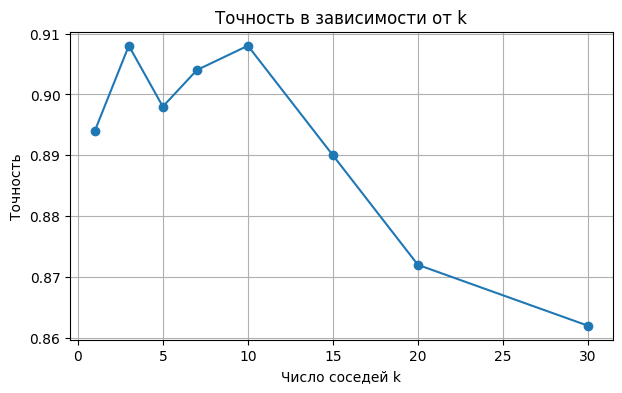

Лучшее k: 3


In [ ]:
k_values = [1, 3, 5, 7, 10, 15, 20, 30]
k_scores = []
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(small_train, small_labels)
    k_scores.append(model.score(small_test, small_test_labels))

plt.figure(figsize=(7, 4))
plt.plot(k_values, k_scores, marker="o")
plt.xlabel("Число соседей k")
plt.ylabel("Точность")
plt.title("Точность в зависимости от k")
plt.grid(True)
plt.show()
print("Лучшее k:", k_values[int(np.argmax(k_scores))])

## 5. PCA перед классификацией

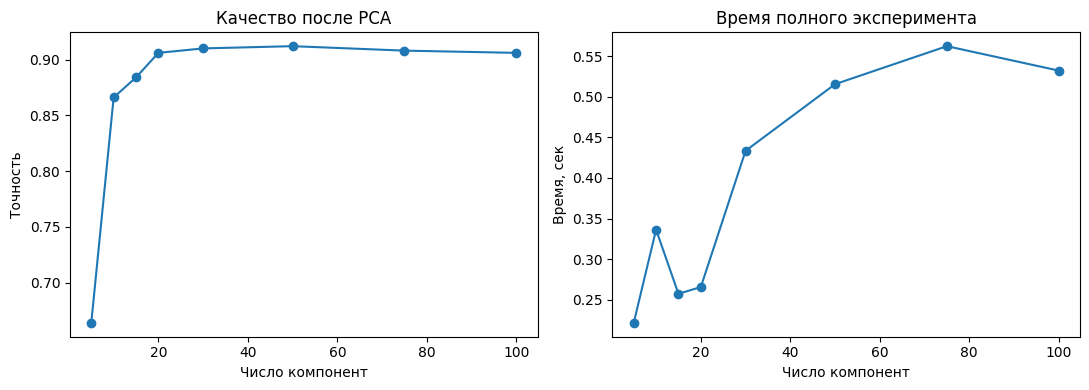

Лучшее число компонент: 50
Наибольшая точность: 0.912


In [ ]:
component_values = [5, 10, 15, 20, 30, 50, 75, 100]
pca_scores = []
pca_times = []

for n_comp in component_values:
    start = time.time()
    reducer = PCA(n_components=n_comp, svd_solver="randomized", random_state=42)
    train_reduced = reducer.fit_transform(small_train)
    test_reduced = reducer.transform(small_test)
    model = KNeighborsClassifier(n_neighbors=5)
    model.fit(train_reduced, small_labels)
    pca_scores.append(model.score(test_reduced, small_test_labels))
    pca_times.append(time.time() - start)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(component_values, pca_scores, marker="o")
ax[0].set(xlabel="Число компонент", ylabel="Точность", title="Качество после PCA")
ax[1].plot(component_values, pca_times, marker="o")
ax[1].set(xlabel="Число компонент", ylabel="Время, сек", title="Время полного эксперимента")
plt.tight_layout()
plt.show()
print("Лучшее число компонент:", component_values[int(np.argmax(pca_scores))])
print("Наибольшая точность:", round(max(pca_scores), 4))

## 6. Совместный подбор параметров

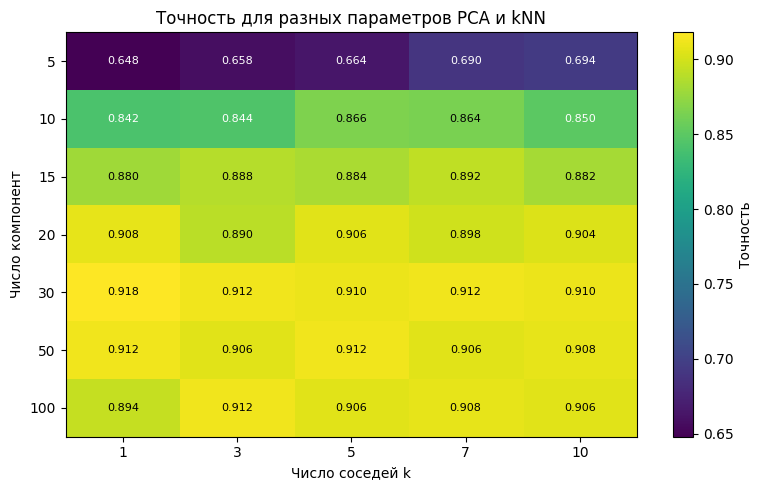

Лучшая комбинация: 30 компонент, k = 1 точность = 0.918
Худшая комбинация: 5 компонент, k = 1 точность = 0.648


In [ ]:
component_grid = [5, 10, 15, 20, 30, 50, 100]
k_grid = [1, 3, 5, 7, 10]
score_grid = np.zeros((len(component_grid), len(k_grid)))

for i, n_comp in enumerate(component_grid):
    reducer = PCA(n_components=n_comp, svd_solver="randomized", random_state=42)
    train_reduced = reducer.fit_transform(small_train)
    test_reduced = reducer.transform(small_test)
    for j, k in enumerate(k_grid):
        model = KNeighborsClassifier(n_neighbors=k)
        model.fit(train_reduced, small_labels)
        score_grid[i, j] = model.score(test_reduced, small_test_labels)

plt.figure(figsize=(8, 5))
plt.imshow(score_grid, aspect="auto", cmap="viridis")
plt.colorbar(label="Точность")
plt.xticks(range(len(k_grid)), k_grid)
plt.yticks(range(len(component_grid)), component_grid)
plt.xlabel("Число соседей k")
plt.ylabel("Число компонент")
plt.title("Точность для разных параметров PCA и kNN")
for i in range(len(component_grid)):
    for j in range(len(k_grid)):
        plt.text(j, i, f"{score_grid[i, j]:.3f}", ha="center", va="center", color="white" if score_grid[i,j] < score_grid.mean() else "black", fontsize=8)
plt.tight_layout()
plt.show()
best = np.unravel_index(np.argmax(score_grid), score_grid.shape)
worst = np.unravel_index(np.argmin(score_grid), score_grid.shape)
print("Лучшая комбинация:", component_grid[best[0]], "компонент, k =", k_grid[best[1]], "точность =", round(score_grid[best], 4))
print("Худшая комбинация:", component_grid[worst[0]], "компонент, k =", k_grid[worst[1]], "точность =", round(score_grid[worst], 4))

## 7. Выводы

In [ ]:
print("1. PCA переводит исходные признаки в новые направления, упорядоченные по объясняемой дисперсии.")
print("2. kNN определяет класс по меткам ближайших объектов и не требует сложного этапа обучения.")
print("3. Малое число компонент ускоряет обработку, но может потерять признаки, важные для распознавания.")
print("4. Оптимальное число компонент и соседей определяется по результатам экспериментов выше.")
print("5. Наиболее трудной частью было реализовать преобразования и сравнить несколько вариантов классификации.")
print("6. Интереснее всего наблюдать, как меняется точность при изменении размерности данных.")

1. PCA переводит исходные признаки в новые направления, упорядоченные по объясняемой дисперсии.
2. kNN определяет класс по меткам ближайших объектов и не требует сложного этапа обучения.
3. Малое число компонент ускоряет обработку, но может потерять признаки, важные для распознавания.
4. Оптимальное число компонент и соседей определяется по результатам экспериментов выше.
5. Наиболее трудной частью было реализовать преобразования и сравнить несколько вариантов классификации.
6. Интереснее всего наблюдать, как меняется точность при изменении размерности данных.
